# Week 2 homework

Data: 2024 American Time Use Survey, US Bureau of Labor Statistics.
Each row contains an estimated average or difference in daily working hours,
with confidence limits. Variable definitions are in `data/README.md`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("data/working_time.csv")
data.head()

,day_type,measure,series,estimate_hours,ci_low_hours,ci_high_hours
0,Weekdays,Job-related work,Men,7.857500,7.558580,8.156420
1,Weekdays,Household and care work,Men,1.838531,1.623811,2.053251
2,Weekdays,Combined work,Men,9.696031,9.368479,10.023582
3,Weekdays,Job-related work,Women,6.741170,6.357812,7.124529
4,Weekdays,Household and care work,Women,2.635240,2.440795,2.829685


In [3]:
gaps = data[data["series"] == "Women minus men"].copy()
gaps["error_low"] = gaps["estimate_hours"] - gaps["ci_low_hours"]
gaps["error_high"] = gaps["ci_high_hours"] - gaps["estimate_hours"]
weekdays = gaps[gaps["day_type"] == "Weekdays"]
weekends = gaps[gaps["day_type"] == "Weekends and holidays"]
print(weekdays[["measure", "estimate_hours", "ci_low_hours", "ci_high_hours"]].round(2))
print(weekends[["measure", "estimate_hours", "ci_low_hours", "ci_high_hours"]].round(2))

                   measure  estimate_hours  ci_low_hours  ci_high_hours
6         Job-related work           -1.12         -1.59          -0.64
7  Household and care work            0.80          0.52           1.07
8            Combined work           -0.32         -0.79           0.15
                    measure  estimate_hours  ci_low_hours  ci_high_hours
15         Job-related work           -0.31         -0.75           0.13
16  Household and care work            0.78          0.40           1.16
17            Combined work            0.47          0.03           0.92


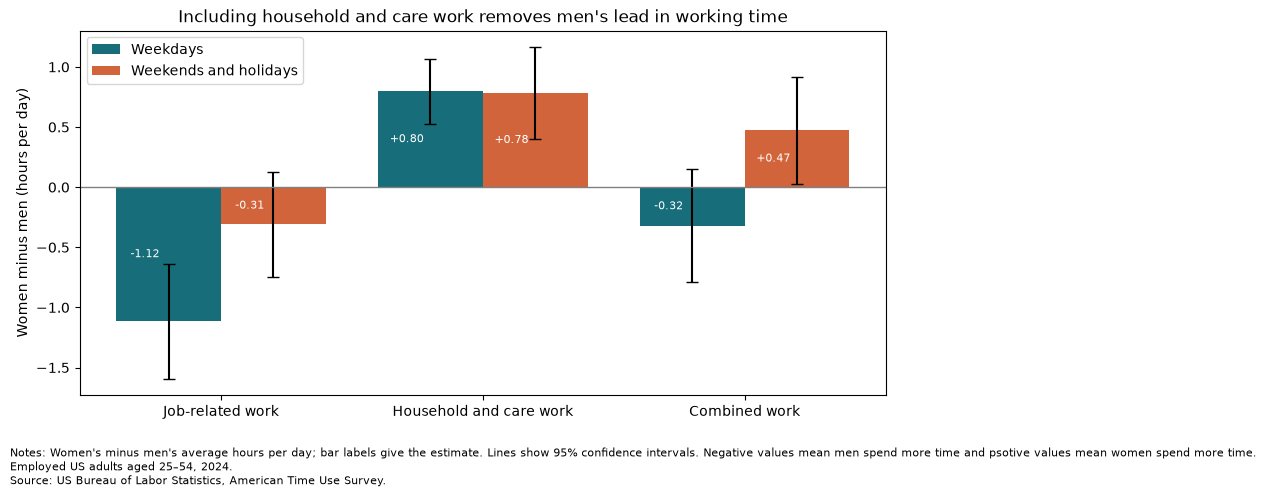

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar([0, 1, 2], weekdays["estimate_hours"], width=0.4,
       yerr=[weekdays["error_low"], weekdays["error_high"]], capsize=4,
       color="#176D79", label="Weekdays")
ax.bar([0.4, 1.4, 2.4], weekends["estimate_hours"], width=0.4,
       yerr=[weekends["error_low"], weekends["error_high"]], capsize=4,
       color="#D2643B", label="Weekends and holidays")
ax.axhline(0, color="grey", linewidth=1)
# Write each value inside its bar, left of the interval line, halfway between zero and the bar's end.
for position, value in zip([0, 1, 2, 0.4, 1.4, 2.4],
                           list(weekdays["estimate_hours"]) + list(weekends["estimate_hours"]), strict=True):
    ax.annotate(f"{value:+.2f}", (position, value / 2), xytext=(-17, 0), textcoords="offset points",
                ha="center", va="center", color="white", fontsize=8)
ax.set(title="Including household and care work removes men's lead in working time",
       ylabel="Women minus men (hours per day)", xticks=[0.2, 1.2, 2.2],
       xticklabels=["Job-related work", "Household and care work", "Combined work"])
ax.legend()
fig.text(0.01, 0.02,
         "Notes: Women's minus men's average hours per day; bar labels give the estimate. Lines show 95% confidence intervals. Negative values mean men spend more time and psotive values mean women spend more time.\n"
         "Employed US adults aged 25–54, 2024.\n"
         "Source: US Bureau of Labor Statistics, American Time Use Survey.",
         fontsize=8)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig("figures/working_time_gap.png", dpi=150, bbox_inches="tight")
plt.show()